In [1]:
import pandas as pd

scores = pd.read_csv("/home/andrey/Codes/osu-pp-predict/osu_scores_dataset.csv")

In [8]:
scores.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 1508 entries, 0 to 1507
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   timestamp_utc          1508 non-null   str    
 1   username               1508 non-null   str    
 2   song_artist            1508 non-null   str    
 3   song_title             1508 non-null   str    
 4   difficulty_name        1508 non-null   str    
 5   creator                1508 non-null   str    
 6   beatmap_hash           1508 non-null   str    
 7   score                  1508 non-null   int64  
 8   accuracy               1508 non-null   float64
 9   pp                     1508 non-null   float64
 10  stars                  1508 non-null   float64
 11  aim                    1508 non-null   float64
 12  speed                  1508 non-null   float64
 13  flashlight             1508 non-null   float64
 14  slider_factor          1508 non-null   float64
 15  max_combo      

In [2]:

import pandas as pd
from sklearn.model_selection import TimeSeriesSplit

# 1. Переводим в datetime и сортируем по времени
scores['timestamp_utc'] = pd.to_datetime(scores['timestamp_utc'])
scores = scores.sort_values('timestamp_utc').reset_index(drop=True)

# 2. Простой хронологический сплит (80 / 20)
train_size = int(len(scores) * 0.8)
train_df = scores.iloc[:train_size]
test_df = scores.iloc[train_size:]

In [10]:
train_df.head()

,timestamp_utc,username,song_artist,song_title,difficulty_name,creator,beatmap_hash,score,accuracy,pp,...,rhythm_complexity,dominant_meter,kiai_duration_percent,kiai_density_ratio,kiai_spacing_ratio,mods,n300,n100,n50,n_miss
0,2025-12-30 11:42:01.788888+00:00,superlimon,"Culprate, Keota & Sophie Meiers",Mechanic Heartbeat,Normal,pishifat,e2a0cce07c97493e2f7255cf3076a4e2,2207050,93.39,8.46,...,0.0,4,0.00,NaN,NaN,0,248,26,1,0
1,2025-12-30 12:11:36.044560+00:00,superlimon,DJ OKAWARI,Flower Dance,Little's Insane,Narcissu,25a63e7d375da46e74c12b0455de7be4,2014306,86.02,34.22,...,0.0,4,53.93,1.31,1.16,0,556,126,4,10
2,2025-12-30 12:37:06.351848+00:00,superlimon,dora,Doradura,Collab Hard,Shmiklak,5a865daccfaafe1d24662739e64899d7,464258,85.28,14.80,...,0.0,4,30.85,1.49,1.34,0,227,38,10,8
3,2025-12-30 12:46:45.875992+00:00,superlimon,dora,Doradura,Collab Expert,Shmiklak,a8332bfea3adc2207a1e6c4a11f13edb,313708,77.62,38.85,...,0.0,4,30.88,1.58,1.23,0,247,79,4,23
4,2025-12-30 12:51:06.706712+00:00,superlimon,dora,Doradura,Testo's <3,Shmiklak,ca14ed2b52cd08f75b1269f8fd22ca1b,152655,65.66,22.09,...,0.0,4,30.88,1.72,1.18,1,224,107,10,57


In [3]:
from sklearn.base import BaseEstimator, TransformerMixin


class SecondsSinceFirstScore(BaseEstimator, TransformerMixin):
    def __init__(self, column="timestamp_utc"):
        self.column = column

    def fit(self, X, y=None):
        timestamps = pd.to_datetime(X[self.column], utc=True).dropna()
        if timestamps.empty:
            raise ValueError(f"Column {self.column!r} has no valid timestamps")
        self.origin_ = timestamps.min()
        return self

    def transform(self, X):
        if not hasattr(self, "origin_"):
            raise RuntimeError("Call fit before transform")
        X_ = X.copy()
        timestamps = pd.to_datetime(X_[self.column], utc=True)
        X_["seconds_since_first_score"] = (timestamps - self.origin_).dt.total_seconds()
        return X_

    def get_feature_names_out(self, input_features=None):
        return ["seconds_since_first_score"]



In [4]:
import re
from sklearn.base import BaseEstimator, TransformerMixin


class DifficultyNameTransformer(BaseEstimator, TransformerMixin):
    _difficulty_ranks = {
        "beginner": 0,
        "easy": 1,
        "normal": 2,
        "advanced": 3,
        "hard": 4,
        "hyper": 5,
        "insane": 6,
        "expert": 7,
        "extra": 8,
        "extreme": 9,
    }

    def __init__(self, column="difficulty_name"):
        self.column = column

    def fit(self, X, y=None):
        if self.column not in X.columns:
            raise ValueError(f"Column {self.column!r} is missing from input")
        self.is_fitted_ = True
        return self

    def transform(self, X):
        if not hasattr(self, "is_fitted_"):
            raise RuntimeError("Call fit before transform")
        if self.column not in X.columns:
            raise ValueError(f"Column {self.column!r} is missing from input")

        X_ = X.copy()
        X_[self.column] = X_[self.column].map(self._canonical_difficulty)
        return X_

    @classmethod
    def _canonical_difficulty(cls, value):
        if not isinstance(value, str):
            return "Extreme"

        normalized = re.sub(r"[^a-z0-9]+", " ", value.lower()).strip()
        matches = [
            name
            for name in cls._difficulty_ranks
            if re.search(rf"\b{re.escape(name)}\b", normalized)
        ]
        if not matches:
            return "Extreme"
        return max(matches, key=cls._difficulty_ranks.get).title()


In [5]:
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin


class ModsTransformer(BaseEstimator, TransformerMixin):
    _mod_masks = {
        "mod_no_fail": 1,
        "mod_easy": 2,
        "mod_touch_device": 4,
        "mod_hidden": 8,
        "mod_hard_rock": 16,
        "mod_sudden_death": 32,
        "mod_double_time": 64,
        "mod_relax": 128,
        "mod_half_time": 256,
        "mod_nightcore": 512,
        "mod_score_v2": 536870912,
        "mod_mirror": 1073741824,
    }

    def __init__(self, column="mods"):
        self.column = column

    def fit(self, X, y=None):
        if self.column not in X.columns:
            raise ValueError(f"Column {self.column!r} is missing from input")
        self.is_fitted_ = True
        return self

    def transform(self, X):
        if not hasattr(self, "is_fitted_"):
            raise RuntimeError("Call fit before transform")
        if self.column not in X.columns:
            raise ValueError(f"Column {self.column!r} is missing from input")

        masks = pd.to_numeric(X[self.column], errors="raise").fillna(0)
        if (masks.lt(0) | masks.mod(1).ne(0)).any():
            raise ValueError("Mod masks must be non-negative integers")
        masks = masks.astype("int64")

        features = pd.DataFrame(index=X.index)
        features["mod_none"] = masks.eq(0).astype("int8")
        for feature, mask in self._mod_masks.items():
            features[feature] = (masks & mask).ne(0).astype("int8")

        return X.drop(columns=[self.column]).join(features)


mods_transformer = ModsTransformer()

In [21]:
train_df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 1206 entries, 0 to 1205
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   timestamp_utc          1206 non-null   datetime64[us, UTC]
 1   username               1206 non-null   str                
 2   song_artist            1206 non-null   str                
 3   song_title             1206 non-null   str                
 4   difficulty_name        1206 non-null   str                
 5   creator                1206 non-null   str                
 6   beatmap_hash           1206 non-null   str                
 7   score                  1206 non-null   int64              
 8   accuracy               1206 non-null   float64            
 9   pp                     1206 non-null   float64            
 10  stars                  1206 non-null   float64            
 11  aim                    1206 non-null   float64            
 12  spe

In [6]:
columns_to_drop = ['song_title', 'song_artist', 'beatmap_hash', 'mods']
score_features = ['score', 'accuracy', 'pp', 'max_combo', 'n300', 'n100', 'n50', 'n_miss', 'username']

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin


class DropFeaturesTransformer(BaseEstimator, TransformerMixin):
    _allowed_targets = {"accuracy", "pp", "n_miss"}

    def __init__(self, columns_to_drop, score_features, target=None):
        self.columns_to_drop = columns_to_drop
        self.score_features = score_features
        self.target = target

    def fit(self, X, y=None):
        if self.target is not None and self.target not in self._allowed_targets:
            raise ValueError(
                f"target must be one of {sorted(self._allowed_targets)} or None"
            )
        if self.target is not None and self.target not in X.columns:
            raise ValueError(f"Target column {self.target!r} is missing from input")
        return self

    def transform(self, X):
        if self.target is not None and self.target not in self._allowed_targets:
            raise ValueError(
                f"target must be one of {sorted(self._allowed_targets)} or None"
            )

        columns = set(self.columns_to_drop) | set(self.score_features)
        if self.target is not None:
            columns.discard(self.target)
        return X.drop(columns=list(columns), errors="ignore")



In [36]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1206 entries, 0 to 1205
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   timestamp_utc          1206 non-null   datetime64[us, UTC]
 1   username               1206 non-null   str                
 2   song_artist            1206 non-null   str                
 3   song_title             1206 non-null   str                
 4   difficulty_name        1206 non-null   str                
 5   creator                1206 non-null   str                
 6   beatmap_hash           1206 non-null   str                
 7   score                  1206 non-null   int64              
 8   accuracy               1206 non-null   float64            
 9   pp                     1206 non-null   float64            
 10  stars                  1206 non-null   float64            
 11  aim                    1206 non-null   float64            
 12  spe

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def kiai_numeric_columns(X):
    return [
        column
        for column in X.select_dtypes(include="number").columns
        if "kiai" in column.lower()
    ]


def other_numeric_columns(X):
    return [
        column
        for column in X.select_dtypes(include="number").columns
        if "kiai" not in column.lower()
    ]


def categorical_columns(X):
    return X.select_dtypes(exclude="number").columns.tolist()


numeric_kiai_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value=1.0)),
        ("scaler", StandardScaler()),
    ]
)

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="mean", keep_empty_features=True)),
        ("scaler", StandardScaler()),
    ]
)

feature_preprocessor = ColumnTransformer(
    transformers=[
        ("kiai", numeric_kiai_pipeline, kiai_numeric_columns),
        ("numeric", numeric_pipeline, other_numeric_columns),
        ("categorical", "passthrough", categorical_columns),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

pp_preprocessing_pipeline = Pipeline(
    steps=[
        ("time", SecondsSinceFirstScore()),
        ("difficulty", DifficultyNameTransformer()),
        ("mods", ModsTransformer()),
        (
            "drop_unused",
            DropFeaturesTransformer(
                columns_to_drop=columns_to_drop + ["timestamp_utc"],
                score_features=score_features,
            ),
        ),
        ("features", feature_preprocessor),
    ]
)

y_train_pp = train_df["pp"].astype("float64")
y_test_pp = test_df["pp"].astype("float64")
X_train_pp = pp_preprocessing_pipeline.fit_transform(train_df)
X_test_pp = pp_preprocessing_pipeline.transform(test_df)

X_train_pp.head()

,kiai_duration_percent,kiai_density_ratio,kiai_spacing_ratio,stars,aim,speed,flashlight,slider_factor,max_map_combo,n_circles,...,mod_hard_rock,mod_sudden_death,mod_double_time,mod_relax,mod_half_time,mod_nightcore,mod_score_v2,mod_mirror,difficulty_name,creator
0,-1.135031,-0.715026,-0.620442,-3.088613,-2.814370,-2.949575,-0.079233,-0.140421,-0.379997,-0.594772,...,-0.142494,-0.028808,-0.560112,-0.049938,-0.076408,-0.040757,0.0,0.0,Normal,pishifat
1,1.709318,0.430155,0.060988,-1.146542,-1.119634,-0.830601,-0.079233,0.353099,0.428080,0.246652,...,-0.142494,-0.028808,-0.560112,-0.049938,-0.076408,-0.040757,0.0,0.0,Insane,Narcissu
2,0.492044,1.095098,0.827597,-2.075723,-1.896972,-1.930088,-0.079233,-0.563438,-0.351034,-0.652580,...,-0.142494,-0.028808,-0.560112,-0.049938,-0.076408,-0.040757,0.0,0.0,Hard,Shmiklak
3,0.493627,1.427570,0.359114,-0.309442,-0.244254,-0.268549,-0.079233,-0.316678,-0.277177,-0.475945,...,-0.142494,-0.028808,-0.560112,-0.049938,-0.076408,-0.040757,0.0,0.0,Expert,Shmiklak
4,0.493627,1.944749,0.146167,0.176076,0.314589,-0.188550,-0.079233,0.176842,-0.177254,-0.363541,...,-0.142494,-0.028808,-0.560112,-0.049938,-0.076408,-0.040757,0.0,0.0,Extreme,Shmiklak


In [9]:
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Keep the latest part of train_df for chronological early stopping.
validation_size = max(1, int(len(train_df) * 0.15))
fit_df = train_df.iloc[:-validation_size]
validation_df = train_df.iloc[-validation_size:]

validation_preprocessor = clone(pp_preprocessing_pipeline)
X_fit = validation_preprocessor.fit_transform(fit_df)
X_validation = validation_preprocessor.transform(validation_df)
y_fit = fit_df["pp"].astype("float64")
y_validation = validation_df["pp"].astype("float64")

categorical_features = X_fit.select_dtypes(exclude="number").columns.tolist()


def prepare_catboost_features(X):
    X = X.copy()
    for column in categorical_features:
        X[column] = X[column].astype("string").fillna("__MISSING__").astype(str)
    return X


X_fit = prepare_catboost_features(X_fit)
X_validation = prepare_catboost_features(X_validation)

validation_model = CatBoostRegressor(
    iterations=3000,
    learning_rate=0.03,
    depth=6,
    loss_function="RMSE",
    eval_metric="RMSE",
    one_hot_max_size=10,
    random_seed=42,
    verbose=200,
    allow_writing_files=False,
)
validation_model.fit(
    X_fit,
    y_fit,
    cat_features=categorical_features,
    eval_set=(X_validation, y_validation),
    early_stopping_rounds=150,
    use_best_model=True,
)

validation_predictions = validation_model.predict(X_validation)
validation_rmse = mean_squared_error(y_validation, validation_predictions) ** 0.5
validation_mae = mean_absolute_error(y_validation, validation_predictions)
print(f"Validation RMSE: {validation_rmse:.3f}")
print(f"Validation MAE:  {validation_mae:.3f}")

# Refit preprocessing and the model on the full training period.
final_iterations = max(1, validation_model.get_best_iteration() + 1)
pp_preprocessing_pipeline.fit(train_df)
X_train_catboost = prepare_catboost_features(
    pp_preprocessing_pipeline.transform(train_df)
)
X_test_catboost = prepare_catboost_features(
    pp_preprocessing_pipeline.transform(test_df)
)
y_train_catboost = train_df["pp"].astype("float64")
y_test_catboost = test_df["pp"].astype("float64")

pp_model = CatBoostRegressor(
    iterations=final_iterations,
    learning_rate=0.03,
    depth=6,
    loss_function="RMSE",
    eval_metric="RMSE",
    one_hot_max_size=10,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)
pp_model.fit(
    X_train_catboost,
    y_train_catboost,
    cat_features=categorical_features,
)

pp_predictions = pp_model.predict(X_test_catboost)
test_rmse = mean_squared_error(y_test_catboost, pp_predictions) ** 0.5
test_mae = mean_absolute_error(y_test_catboost, pp_predictions)
test_r2 = r2_score(y_test_catboost, pp_predictions)
print(f"Test RMSE: {test_rmse:.3f}")
print(f"Test MAE:  {test_mae:.3f}")
print(f"Test R2:   {test_r2:.3f}")
print(f"Best iterations: {final_iterations}")

0:	learn: 37.5181475	test: 41.4702777	best: 41.4702777 (0)	total: 54.2ms	remaining: 2m 42s
200:	learn: 20.3014307	test: 31.5422123	best: 31.4817287 (188)	total: 272ms	remaining: 3.78s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 31.48172865
bestIteration = 188

Shrink model to first 189 iterations.
Validation RMSE: 31.482
Validation MAE:  18.508
Test RMSE: 27.162
Test MAE:  20.264
Test R2:   0.287
Best iterations: 189


Validation comparison (winner chosen without looking at the holdout test set):


,task,model,validation_RMSE,validation_MAE,validation_R2,validation_AP,validation_ROC_AUC,validation_F1_at_0.5,test_RMSE,test_MAE,test_R2,test_AP,test_ROC_AUC,test_F1_at_0.5,test_Brier,test_Accuracy
0,accuracy,Random forest,6.9860,5.0290,0.6975,NaN,NaN,NaN,7.4005,5.7373,0.3931,NaN,NaN,NaN,NaN,NaN
1,accuracy,Extra trees,7.2339,5.1828,0.6757,NaN,NaN,NaN,7.3559,5.5998,0.4004,NaN,NaN,NaN,NaN,NaN
2,accuracy,Gradient boosting,7.5694,5.9277,0.6449,NaN,NaN,NaN,7.9732,6.5804,0.2955,NaN,NaN,NaN,NaN,NaN
3,accuracy,CatBoost,7.8146,6.1525,0.6215,NaN,NaN,NaN,7.7629,6.3108,0.3322,NaN,NaN,NaN,NaN,NaN
4,accuracy,Hist. gradient boosting,7.8730,6.2208,0.6159,NaN,NaN,NaN,7.3265,5.9676,0.4052,NaN,NaN,NaN,NaN,NaN
5,accuracy,KNN,7.9933,5.8957,0.6040,NaN,NaN,NaN,8.2490,6.5406,0.2460,NaN,NaN,NaN,NaN,NaN
6,accuracy,AdaBoost,8.0370,6.4060,0.5997,NaN,NaN,NaN,9.2387,7.9739,0.0542,NaN,NaN,NaN,NaN,NaN
7,accuracy,Decision tree,8.9427,6.5785,0.5044,NaN,NaN,NaN,8.3289,6.6239,0.2313,NaN,NaN,NaN,NaN,NaN
8,accuracy,Ridge,10.7386,7.0975,0.2853,NaN,NaN,NaN,9.4552,6.7243,0.0093,NaN,NaN,NaN,NaN,NaN
9,accuracy,Dummy median,13.1353,9.5830,-0.0693,NaN,NaN,NaN,10.3405,8.7729,-0.1849,NaN,NaN,NaN,NaN,NaN


Selected models and final chronological holdout results:


,task,model,validation_RMSE,validation_MAE,validation_R2,validation_AP,validation_ROC_AUC,validation_F1_at_0.5,test_RMSE,test_MAE,test_R2,test_AP,test_ROC_AUC,test_F1_at_0.5,test_Brier,test_Accuracy
0,pp,CatBoost,31.8805,18.2765,0.4034,NaN,NaN,NaN,27.3762,20.1851,0.2760,NaN,NaN,NaN,NaN,NaN
1,accuracy,Random forest,6.9860,5.0290,0.6975,NaN,NaN,NaN,7.4005,5.7373,0.3931,NaN,NaN,NaN,NaN,NaN
2,zero_miss,Random forest,NaN,NaN,NaN,1.0,1.0,0.0,NaN,NaN,NaN,0.1956,0.7227,0.1875,0.0562,0.9139


No-miss prevalence | fit: 3.6%, validation: 0.6%, test: 4.3%


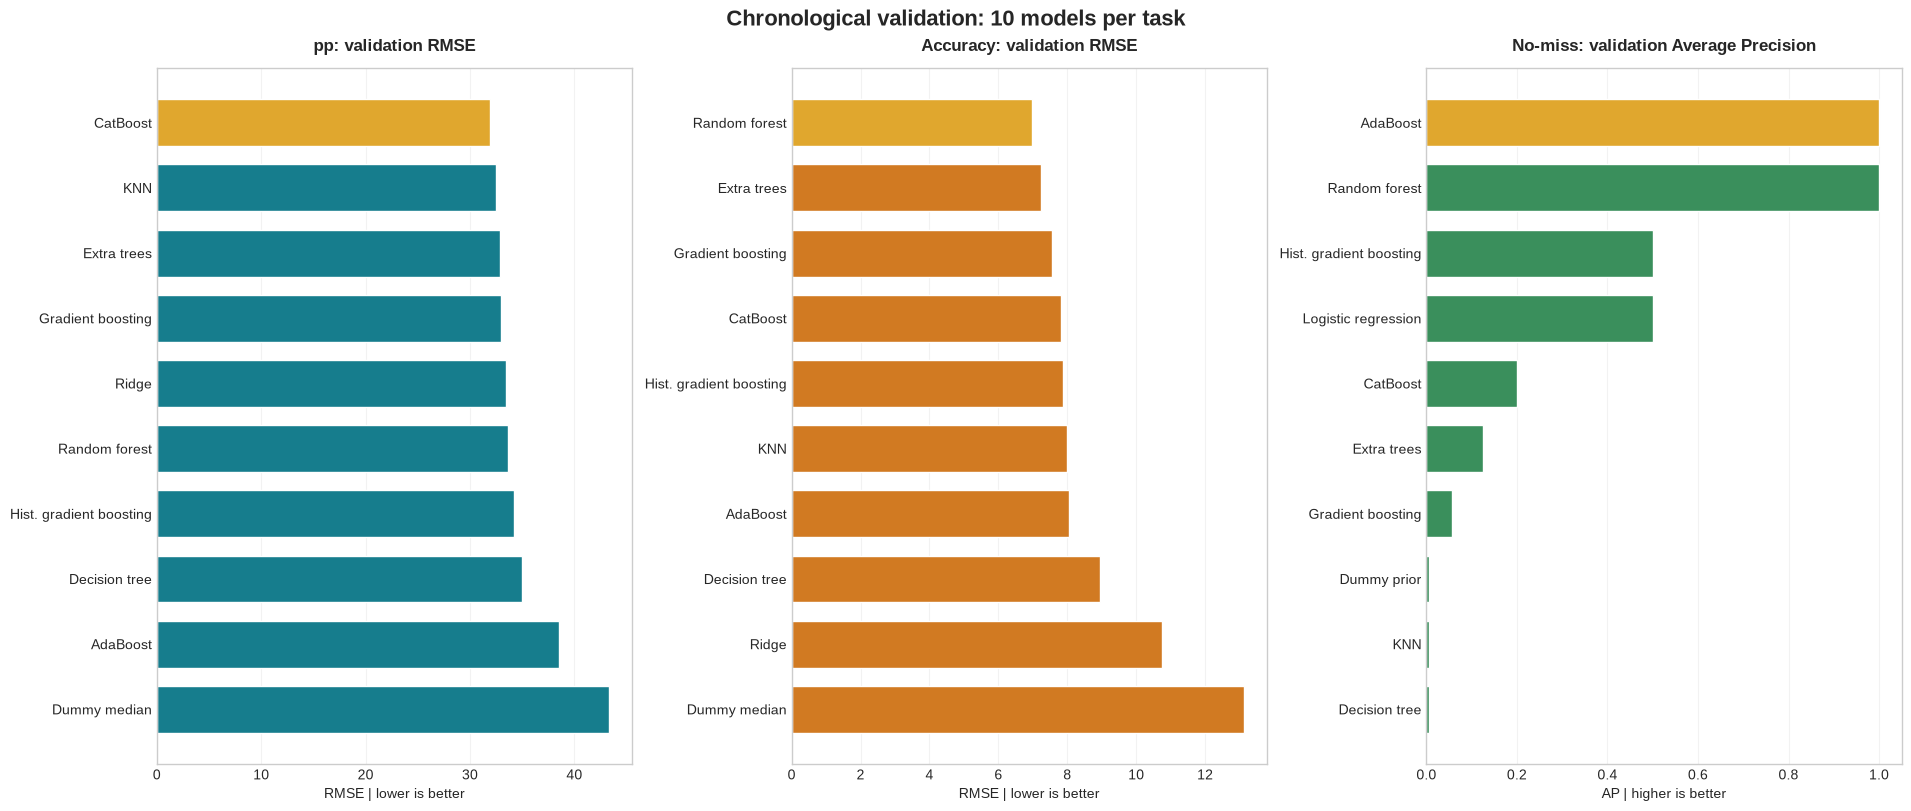

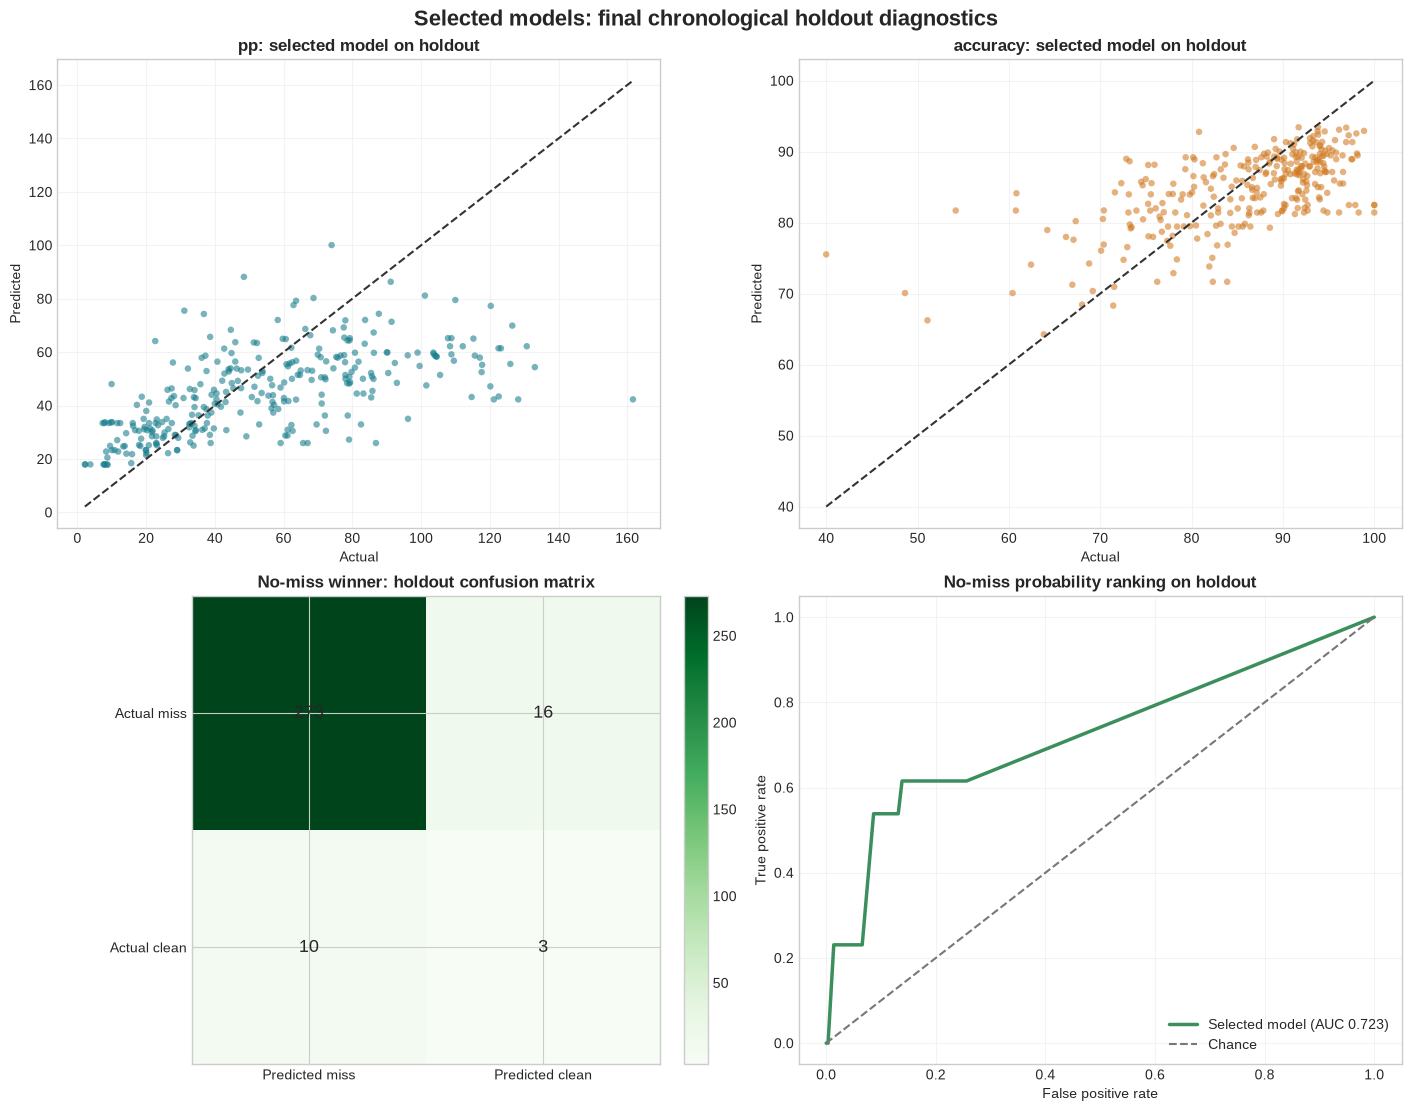

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, CatBoostRegressor
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    AdaBoostRegressor,
    ExtraTreesClassifier,
    ExtraTreesRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor


# X matrices come from the existing chronological preprocessing pipeline, which drops all score-result columns.
leakage_columns = {"pp", "accuracy", "n_miss"}
assert not (leakage_columns & set(X_fit.columns)), "A target leaked into the model features"
assert not (leakage_columns & set(X_train_catboost.columns)), "A target leaked into the test features"
assert "n_miss" in fit_df.columns and "n_miss" in train_df.columns

benchmark_categorical_features = X_fit.select_dtypes(exclude="number").columns.tolist()
numeric_features = X_fit.select_dtypes(include="number").columns.tolist()


def make_sklearn_pipeline(estimator):
    numeric_pipeline = Pipeline(
        steps=[("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
    )
    categorical_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=2,
                    sparse_output=False,
                ),
            ),
        ]
    )
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_features),
            ("categorical", categorical_pipeline, benchmark_categorical_features),
        ],
        remainder="drop",
    )
    return Pipeline(steps=[("features", preprocessor), ("model", estimator)])


def regression_candidates():
    return [
        ("Dummy median", __import__("sklearn.dummy", fromlist=["DummyRegressor"]).DummyRegressor(strategy="median")),
        ("Ridge", Ridge(alpha=10.0)),
        ("KNN", KNeighborsRegressor(n_neighbors=15, weights="distance")),
        ("Decision tree", DecisionTreeRegressor(max_depth=5, min_samples_leaf=8, random_state=42)),
        ("Random forest", RandomForestRegressor(n_estimators=250, max_features=0.8, min_samples_leaf=2, n_jobs=-1, random_state=42)),
        ("Extra trees", ExtraTreesRegressor(n_estimators=250, max_features=0.8, min_samples_leaf=2, n_jobs=-1, random_state=42)),
        ("Gradient boosting", GradientBoostingRegressor(n_estimators=150, learning_rate=0.04, max_depth=2, loss="huber", random_state=42)),
        ("Hist. gradient boosting", HistGradientBoostingRegressor(max_iter=150, max_leaf_nodes=15, l2_regularization=1.0, random_state=42)),
        ("AdaBoost", AdaBoostRegressor(n_estimators=120, learning_rate=0.03, random_state=42)),
        ("CatBoost", CatBoostRegressor(iterations=250, learning_rate=0.03, depth=6, loss_function="RMSE", verbose=False, allow_writing_files=False, thread_count=4, random_seed=42)),
    ]


def classification_candidates():
    from sklearn.dummy import DummyClassifier

    return [
        ("Dummy prior", DummyClassifier(strategy="prior")),
        ("Logistic regression", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=42)),
        ("KNN", KNeighborsClassifier(n_neighbors=15, weights="distance")),
        ("Decision tree", DecisionTreeClassifier(max_depth=5, min_samples_leaf=8, class_weight="balanced", random_state=42)),
        ("Random forest", RandomForestClassifier(n_estimators=250, max_features=0.8, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=42)),
        ("Extra trees", ExtraTreesClassifier(n_estimators=250, max_features=0.8, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=42)),
        ("Gradient boosting", GradientBoostingClassifier(n_estimators=150, learning_rate=0.04, max_depth=2, random_state=42)),
        ("Hist. gradient boosting", HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=15, l2_regularization=1.0, random_state=42)),
        ("AdaBoost", AdaBoostClassifier(n_estimators=120, learning_rate=0.03, random_state=42)),
        ("CatBoost", CatBoostClassifier(iterations=250, learning_rate=0.03, depth=6, loss_function="Logloss", auto_class_weights="Balanced", verbose=False, allow_writing_files=False, thread_count=4, random_seed=42)),
    ]


def fit_candidate(name, estimator, X, y):
    if name == "CatBoost":
        estimator.fit(X, y, cat_features=benchmark_categorical_features)
        return estimator
    model = make_sklearn_pipeline(clone(estimator))
    model.fit(X, y)
    return model


def positive_probability(model, X):
    probabilities = model.predict_proba(X)
    if hasattr(model, "classes_"):
        classes = list(model.classes_)
    else:
        classes = list(model.named_steps["model"].classes_)
    return probabilities[:, classes.index(1)]


validation_rows = []
test_rows = []
winner_models = {}
winner_test_predictions = {}

for task in ("pp", "accuracy"):
    y_fit_task = fit_df[task].astype("float64")
    y_validation_task = validation_df[task].astype("float64")
    y_train_task = train_df[task].astype("float64")
    y_test_task = test_df[task].astype("float64")
    candidates = regression_candidates()
    task_validation = []

    for model_name, estimator in candidates:
        model = fit_candidate(model_name, estimator, X_fit, y_fit_task)
        predictions = np.asarray(model.predict(X_validation)).reshape(-1)
        rmse = mean_squared_error(y_validation_task, predictions) ** 0.5
        task_validation.append((rmse, model_name))
        validation_rows.append(
            {
                "task": task,
                "model": model_name,
                "validation_RMSE": rmse,
                "validation_MAE": mean_absolute_error(y_validation_task, predictions),
                "validation_R2": r2_score(y_validation_task, predictions),
            }
        )

    winner_name = min(task_validation)[1]
    for model_name, estimator in candidates:
        model = fit_candidate(model_name, estimator, X_train_catboost, y_train_task)
        predictions = np.asarray(model.predict(X_test_catboost)).reshape(-1)
        test_rows.append(
            {
                "task": task,
                "model": model_name,
                "test_RMSE": mean_squared_error(y_test_task, predictions) ** 0.5,
                "test_MAE": mean_absolute_error(y_test_task, predictions),
                "test_R2": r2_score(y_test_task, predictions),
            }
        )
        if model_name == winner_name:
            winner_models[task] = model
            winner_test_predictions[task] = predictions

zero_miss_fit = (pd.to_numeric(fit_df["n_miss"], errors="raise") == 0).astype("int8")
zero_miss_validation = (pd.to_numeric(validation_df["n_miss"], errors="raise") == 0).astype("int8")
zero_miss_train = (pd.to_numeric(train_df["n_miss"], errors="raise") == 0).astype("int8")
zero_miss_test = (pd.to_numeric(test_df["n_miss"], errors="raise") == 0).astype("int8")
if zero_miss_fit.nunique() != 2 or zero_miss_validation.nunique() != 2:
    raise ValueError("The fit and validation periods must both contain scores with and without misses")

classification_validation = []
for model_name, estimator in classification_candidates():
    model = fit_candidate(model_name, estimator, X_fit, zero_miss_fit)
    probabilities = positive_probability(model, X_validation)
    average_precision = average_precision_score(zero_miss_validation, probabilities)
    classification_validation.append((average_precision, model_name))
    validation_rows.append(
        {
            "task": "zero_miss",
            "model": model_name,
            "validation_AP": average_precision,
            "validation_ROC_AUC": roc_auc_score(zero_miss_validation, probabilities),
            "validation_F1_at_0.5": f1_score(zero_miss_validation, probabilities >= 0.5, zero_division=0),
        }
    )

zero_miss_winner_name = max(classification_validation)[1]
for model_name, estimator in classification_candidates():
    model = fit_candidate(model_name, estimator, X_train_catboost, zero_miss_train)
    probabilities = positive_probability(model, X_test_catboost)
    test_rows.append(
        {
            "task": "zero_miss",
            "model": model_name,
            "test_AP": average_precision_score(zero_miss_test, probabilities),
            "test_ROC_AUC": roc_auc_score(zero_miss_test, probabilities) if zero_miss_test.nunique() == 2 else np.nan,
            "test_F1_at_0.5": f1_score(zero_miss_test, probabilities >= 0.5, zero_division=0),
            "test_Brier": brier_score_loss(zero_miss_test, probabilities),
            "test_Accuracy": accuracy_score(zero_miss_test, probabilities >= 0.5),
        }
    )
    if model_name == zero_miss_winner_name:
        winner_models["zero_miss"] = model
        winner_test_predictions["zero_miss"] = probabilities

validation_results = pd.DataFrame(validation_rows)
test_results = pd.DataFrame(test_rows)
all_results = validation_results.merge(test_results, on=["task", "model"], how="inner")

winner_rows = []
for task, metric, direction in (
    ("pp", "validation_RMSE", "min"),
    ("accuracy", "validation_RMSE", "min"),
    ("zero_miss", "validation_AP", "max"),
):
    task_rows = all_results[all_results["task"] == task]
    winner_index = task_rows[metric].idxmin() if direction == "min" else task_rows[metric].idxmax()
    winner_rows.append(all_results.loc[winner_index])
winners = pd.DataFrame(winner_rows).reset_index(drop=True)

print("Validation comparison (winner chosen without looking at the holdout test set):")
display(
    all_results.sort_values(["task", "validation_RMSE", "validation_AP"], ascending=[True, True, False])
    .reset_index(drop=True)
    .round(4)
)
print("Selected models and final chronological holdout results:")
display(winners.round(4))
print(
    "No-miss prevalence | fit: {:.1%}, validation: {:.1%}, test: {:.1%}".format(
        zero_miss_fit.mean(), zero_miss_validation.mean(), zero_miss_test.mean()
    )
)

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(19, 8), constrained_layout=True)
plot_specs = [
    ("pp", "validation_RMSE", "pp: validation RMSE", "lower is better", "#167D8D", "min"),
    ("accuracy", "validation_RMSE", "Accuracy: validation RMSE", "lower is better", "#D17A22", "min"),
    ("zero_miss", "validation_AP", "No-miss: validation Average Precision", "higher is better", "#3A8F5C", "max"),
]
for axis, (task, metric, title, direction_label, color, direction) in zip(axes, plot_specs):
    subset = validation_results[validation_results["task"] == task].sort_values(metric, ascending=(direction == "min"))
    best_name = subset.iloc[0]["model"]
    bar_colors = ["#E0A72E" if name == best_name else color for name in subset["model"]]
    axis.barh(subset["model"], subset[metric], color=bar_colors, edgecolor="white", height=0.72)
    axis.set_title(title, fontsize=12, weight="bold", pad=12)
    axis.set_xlabel(metric.replace("validation_", "") + " | " + direction_label)
    axis.grid(axis="x", alpha=0.25)
    axis.grid(axis="y", visible=False)
    axis.invert_yaxis()
fig.suptitle("Chronological validation: 10 models per task", fontsize=16, weight="bold")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)
for axis, task, label, color in (
    (axes[0, 0], "pp", "pp", "#167D8D"),
    (axes[0, 1], "accuracy", "accuracy", "#D17A22"),
):
    actual = test_df[task].to_numpy(dtype=float)
    predicted = winner_test_predictions[task]
    axis.scatter(actual, predicted, s=22, alpha=0.58, color=color, edgecolors="none")
    lower = min(float(actual.min()), float(predicted.min()))
    upper = max(float(actual.max()), float(predicted.max()))
    axis.plot([lower, upper], [lower, upper], linestyle="--", linewidth=1.5, color="#333333")
    axis.set_title(f"{label}: selected model on holdout", weight="bold")
    axis.set_xlabel("Actual")
    axis.set_ylabel("Predicted")
    axis.grid(alpha=0.22)

confusion_axis = axes[1, 0]
probabilities = winner_test_predictions["zero_miss"]
confusion = confusion_matrix(zero_miss_test, probabilities >= 0.5, labels=[0, 1])
image = confusion_axis.imshow(confusion, cmap="Greens")
for row in range(2):
    for column in range(2):
        confusion_axis.text(column, row, str(confusion[row, column]), ha="center", va="center", fontsize=13)
confusion_axis.set_xticks([0, 1], ["Predicted miss", "Predicted clean"])
confusion_axis.set_yticks([0, 1], ["Actual miss", "Actual clean"])
confusion_axis.set_title("No-miss winner: holdout confusion matrix", weight="bold")
fig.colorbar(image, ax=confusion_axis, fraction=0.046, pad=0.04)

roc_axis = axes[1, 1]
if zero_miss_test.nunique() == 2:
    false_positive_rate, true_positive_rate, _ = roc_curve(zero_miss_test, probabilities)
    test_auc = roc_auc_score(zero_miss_test, probabilities)
    roc_axis.plot(false_positive_rate, true_positive_rate, color="#3A8F5C", linewidth=2.5, label=f"Selected model (AUC {test_auc:.3f})")
    roc_axis.plot([0, 1], [0, 1], linestyle="--", color="#777777", label="Chance")
    roc_axis.legend(loc="lower right", frameon=False)
else:
    roc_axis.text(0.5, 0.5, "ROC curve unavailable: test set has one class", ha="center", va="center")
roc_axis.set_title("No-miss probability ranking on holdout", weight="bold")
roc_axis.set_xlabel("False positive rate")
roc_axis.set_ylabel("True positive rate")
roc_axis.grid(alpha=0.22)
fig.suptitle("Selected models: final chronological holdout diagnostics", fontsize=16, weight="bold")
plt.show()

Fold 1: fit=242, validation=241, clean validation scores=2
Fold 2: fit=483, validation=241, clean validation scores=2
Fold 3: fit=724, validation=241, clean validation scores=14
Fold 4: fit=965, validation=241, clean validation scores=2
Pooled walk-forward ranking covers 964 validation scores, including 20 clean scores.
Corrected no-miss ranking (selected by walk-forward Average Precision):


,task,model,selection_AP,selection_ROC_AUC,selection_F1,selection_threshold
0,zero_miss,AdaBoost,0.6825,0.9671,0.7317,0.3271
1,zero_miss,Extra trees,0.6823,0.9703,0.6857,0.3666
2,zero_miss,CatBoost,0.6672,0.9812,0.7111,0.1672
3,zero_miss,Random forest,0.6458,0.9513,0.7111,0.2343
4,zero_miss,Hist. gradient boosting,0.5982,0.9297,0.6667,0.4494
5,zero_miss,Gradient boosting,0.5186,0.9368,0.6222,0.1708
6,zero_miss,Logistic regression,0.5163,0.9483,0.6000,0.9994
7,zero_miss,KNN,0.5009,0.8715,0.6857,0.2037
8,zero_miss,Decision tree,0.4725,0.8898,0.5714,0.7011
9,zero_miss,Dummy prior,0.0170,0.2702,0.0407,0.0304


Final selected models; regression winners use the prior chronological validation, classifier uses walk-forward CV:


,task,model,validation_RMSE,validation_MAE,validation_R2,validation_AP,validation_ROC_AUC,validation_F1_at_0.5,selection_AP,selection_ROC_AUC,...,test_MAE,test_R2,test_AP,test_ROC_AUC,test_F1_at_0.5,test_Brier,test_Accuracy,test_F1_at_selected_threshold,test_Accuracy_at_selected_threshold,threshold_from_walk_forward
0,pp,CatBoost,31.8805,18.2765,0.4034,NaN,NaN,NaN,NaN,NaN,...,20.1851,0.2760,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,accuracy,Random forest,6.9860,5.0290,0.6975,NaN,NaN,NaN,NaN,NaN,...,5.7373,0.3931,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,zero_miss,AdaBoost,NaN,NaN,NaN,NaN,NaN,NaN,0.6825,0.9671,...,NaN,NaN,0.1879,0.8161,0.0,0.0579,0.957,0.2979,0.8907,0.3271


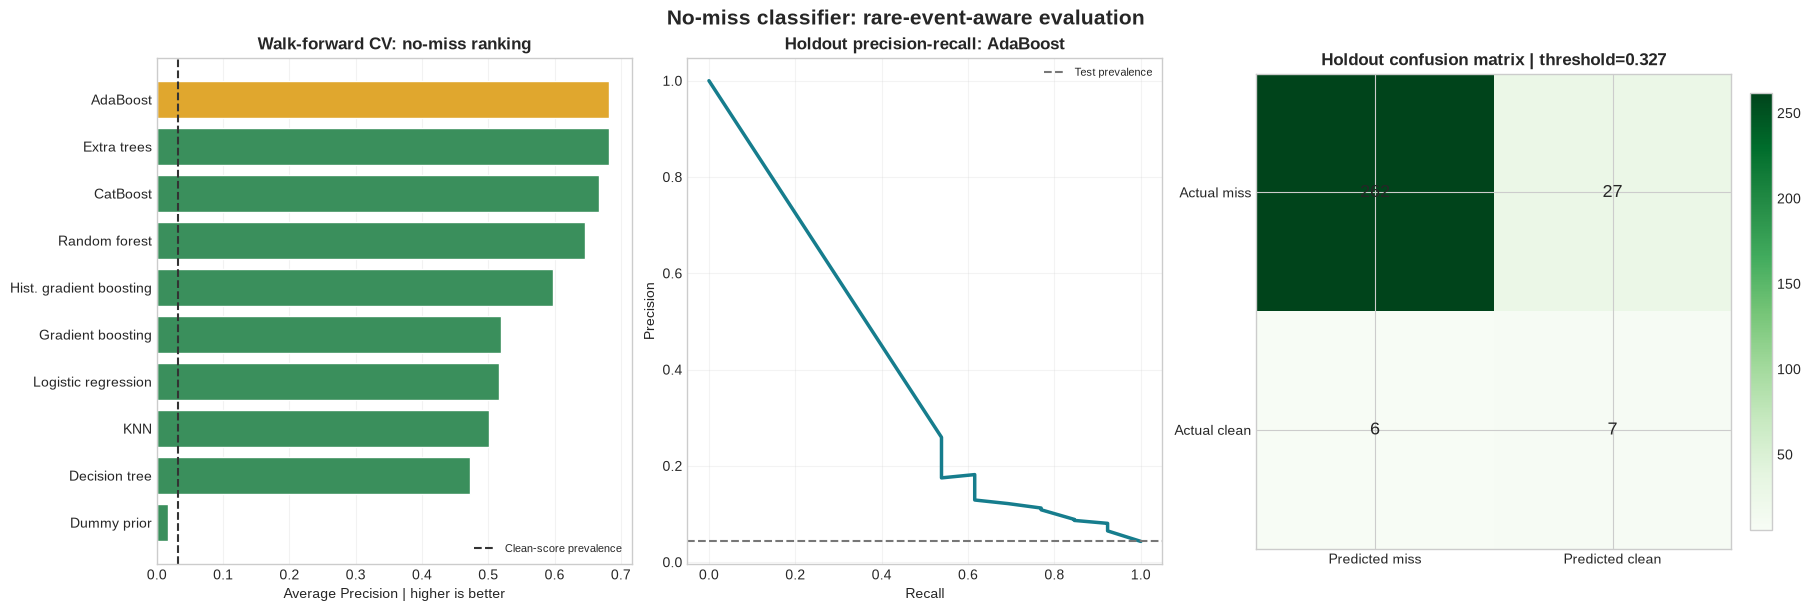

In [11]:
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import TimeSeriesSplit


# The last 15% validation slice contained only one clean score; pool walk-forward predictions instead.
walk_forward = TimeSeriesSplit(n_splits=4)
walk_forward_actual = []
walk_forward_splits = []
for fold_number, (fit_positions, validation_positions) in enumerate(walk_forward.split(train_df), start=1):
    fold_fit_y = zero_miss_train.iloc[fit_positions]
    fold_validation_y = zero_miss_train.iloc[validation_positions]
    walk_forward_splits.append((fit_positions, validation_positions))
    print(
        f"Fold {fold_number}: fit={len(fit_positions)}, validation={len(validation_positions)}, "
        f"clean validation scores={int(fold_validation_y.sum())}"
    )
    if fold_fit_y.nunique() == 2:
        walk_forward_actual.extend(fold_validation_y.tolist())
if sum(walk_forward_actual) < 5:
    raise ValueError("Walk-forward validation needs at least five clean scores for meaningful ranking")


def prepare_fold_features(frame):
    frame = frame.copy()
    for column in benchmark_categorical_features:
        frame[column] = frame[column].astype("string").fillna("__MISSING__").astype(str)
    return frame


classifier_oof = {}
selection_rows = []
classifier_templates = classification_candidates()
for model_name, estimator_template in classifier_templates:
    actual_parts = []
    probability_parts = []
    for fit_positions, validation_positions in walk_forward_splits:
        fold_fit_y = zero_miss_train.iloc[fit_positions]
        if fold_fit_y.nunique() != 2:
            continue
        fold_fit_df = train_df.iloc[fit_positions]
        fold_validation_df = train_df.iloc[validation_positions]
        fold_preprocessor = clone(pp_preprocessing_pipeline)
        fold_X_fit = prepare_fold_features(fold_preprocessor.fit_transform(fold_fit_df))
        fold_X_validation = prepare_fold_features(fold_preprocessor.transform(fold_validation_df))
        model = fit_candidate(
            model_name,
            clone(estimator_template),
            fold_X_fit,
            fold_fit_y,
        )
        fold_probabilities = positive_probability(model, fold_X_validation)
        actual_parts.append(zero_miss_train.iloc[validation_positions].to_numpy())
        probability_parts.append(fold_probabilities)

    oof_actual = np.concatenate(actual_parts)
    oof_probabilities = np.concatenate(probability_parts)
    classifier_oof[model_name] = (oof_actual, oof_probabilities)
    precision, recall, thresholds = precision_recall_curve(oof_actual, oof_probabilities)
    threshold_f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    best_threshold = float(thresholds[int(np.argmax(threshold_f1))]) if len(thresholds) else 0.5
    selection_rows.append(
        {
            "task": "zero_miss",
            "model": model_name,
            "selection_AP": average_precision_score(oof_actual, oof_probabilities),
            "selection_ROC_AUC": roc_auc_score(oof_actual, oof_probabilities),
            "selection_F1": float(np.max(threshold_f1)) if len(threshold_f1) else 0.0,
            "selection_threshold": best_threshold,
        }
    )

selection_results = pd.DataFrame(selection_rows).sort_values("selection_AP", ascending=False).reset_index(drop=True)
zero_miss_winner_name = selection_results.iloc[0]["model"]
zero_miss_threshold = float(selection_results.iloc[0]["selection_threshold"])
zero_miss_winner_estimator = dict(classifier_templates)[zero_miss_winner_name]
zero_miss_winner = fit_candidate(
    zero_miss_winner_name,
    zero_miss_winner_estimator,
    X_train_catboost,
    zero_miss_train,
)
zero_miss_test_probabilities = positive_probability(zero_miss_winner, X_test_catboost)
zero_miss_test_predictions = zero_miss_test_probabilities >= zero_miss_threshold

winner_models["zero_miss"] = zero_miss_winner
winner_test_predictions["zero_miss"] = zero_miss_test_probabilities
validation_results = validation_results[validation_results["task"] != "zero_miss"]
validation_results = pd.concat([validation_results, selection_results], ignore_index=True, sort=False)
selected_test_mask = (test_results["task"] == "zero_miss") & (test_results["model"] == zero_miss_winner_name)
test_results.loc[selected_test_mask, "test_F1_at_selected_threshold"] = f1_score(
    zero_miss_test, zero_miss_test_predictions, zero_division=0
)
test_results.loc[selected_test_mask, "test_Accuracy_at_selected_threshold"] = accuracy_score(
    zero_miss_test, zero_miss_test_predictions
)
test_results.loc[selected_test_mask, "threshold_from_walk_forward"] = zero_miss_threshold
all_results = validation_results.merge(test_results, on=["task", "model"], how="inner")

winner_rows = []
for task, metric, direction in (
    ("pp", "validation_RMSE", "min"),
    ("accuracy", "validation_RMSE", "min"),
    ("zero_miss", "selection_AP", "max"),
):
    task_rows = all_results[all_results["task"] == task]
    winner_index = task_rows[metric].idxmin() if direction == "min" else task_rows[metric].idxmax()
    winner_rows.append(all_results.loc[winner_index])
winners = pd.DataFrame(winner_rows).reset_index(drop=True)

print(
    f"Pooled walk-forward ranking covers {len(walk_forward_actual)} validation scores, "
    f"including {sum(walk_forward_actual)} clean scores."
)
print("Corrected no-miss ranking (selected by walk-forward Average Precision):")
display(selection_results.round(4))
print("Final selected models; regression winners use the prior chronological validation, classifier uses walk-forward CV:")
display(winners.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
ranked = selection_results.sort_values("selection_AP", ascending=True)
bar_colors = ["#E0A72E" if name == zero_miss_winner_name else "#3A8F5C" for name in ranked["model"]]
axes[0].barh(ranked["model"], ranked["selection_AP"], color=bar_colors, edgecolor="white")
axes[0].axvline(zero_miss_train.mean(), linestyle="--", color="#333333", label="Clean-score prevalence")
axes[0].set_title("Walk-forward CV: no-miss ranking", weight="bold")
axes[0].set_xlabel("Average Precision | higher is better")
axes[0].legend(frameon=False, fontsize=8)
axes[0].grid(axis="x", alpha=0.25)
axes[0].grid(axis="y", visible=False)

precision_test, recall_test, _ = precision_recall_curve(zero_miss_test, zero_miss_test_probabilities)
axes[1].plot(recall_test, precision_test, color="#167D8D", linewidth=2.5)
axes[1].axhline(zero_miss_test.mean(), linestyle="--", color="#777777", label="Test prevalence")
axes[1].set_title(f"Holdout precision-recall: {zero_miss_winner_name}", weight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(alpha=0.22)

confusion = confusion_matrix(zero_miss_test, zero_miss_test_predictions, labels=[0, 1])
image = axes[2].imshow(confusion, cmap="Greens")
for row in range(2):
    for column in range(2):
        axes[2].text(column, row, str(confusion[row, column]), ha="center", va="center", fontsize=13)
axes[2].set_xticks([0, 1], ["Predicted miss", "Predicted clean"])
axes[2].set_yticks([0, 1], ["Actual miss", "Actual clean"])
axes[2].set_title(f"Holdout confusion matrix | threshold={zero_miss_threshold:.3f}", weight="bold")
fig.colorbar(image, ax=axes[2], fraction=0.046, pad=0.04)
fig.suptitle("No-miss classifier: rare-event-aware evaluation", fontsize=15, weight="bold")
plt.show()

Probability calibration check on the untouched chronological test set:


,scores,Brier
0,Training-prevalence baseline,0.0413
1,Raw AdaBoost,0.0579
2,Sigmoid-calibrated AdaBoost,0.0650


Calibration did not beat the training-prevalence baseline; treat AdaBoost output as a ranking score, not a calibrated chance.


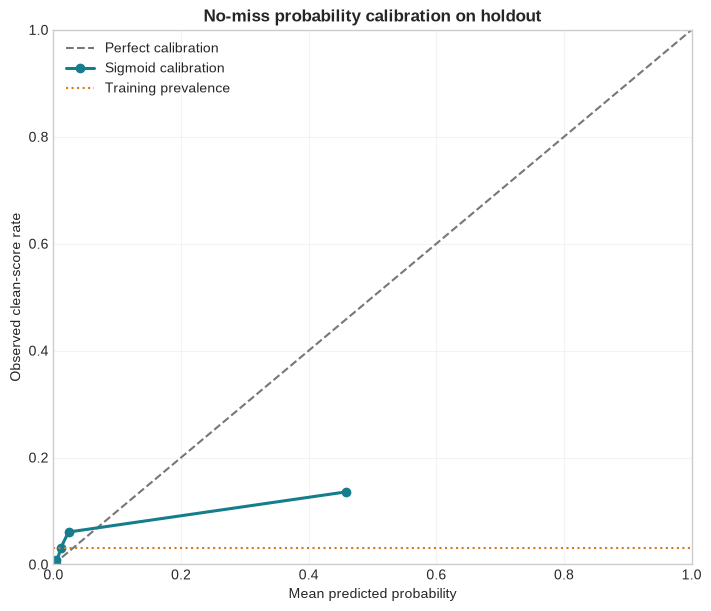

In [13]:
from scipy.special import logit
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression


# Calibrate the selected model's scores using only walk-forward predictions from the training period.
calibration_actual, calibration_raw_scores = classifier_oof[zero_miss_winner_name]
probability_calibrator = LogisticRegression(C=1.0, max_iter=2000, random_state=42)
probability_calibrator.fit(
    logit(np.clip(calibration_raw_scores, 1e-6, 1 - 1e-6)).reshape(-1, 1),
    calibration_actual,
)
raw_test_scores = winner_test_predictions["zero_miss"]
calibrated_test_probabilities = probability_calibrator.predict_proba(
    logit(np.clip(raw_test_scores, 1e-6, 1 - 1e-6)).reshape(-1, 1)
)[:, 1]
training_prevalence = float(zero_miss_train.mean())
baseline_test_brier = brier_score_loss(
    zero_miss_test,
    np.full(len(zero_miss_test), training_prevalence),
)
raw_test_brier = brier_score_loss(zero_miss_test, raw_test_scores)
calibrated_test_brier = brier_score_loss(zero_miss_test, calibrated_test_probabilities)


def predict_zero_miss_score(preprocessed_features):
    """Return the uncalibrated clean-score ranking score; do not interpret it as a probability."""
    feature_frame = prepare_catboost_features(preprocessed_features)
    return positive_probability(winner_models["zero_miss"], feature_frame)


calibration_summary = pd.DataFrame(
    [
        {"scores": "Training-prevalence baseline", "Brier": baseline_test_brier},
        {"scores": "Raw AdaBoost", "Brier": raw_test_brier},
        {"scores": "Sigmoid-calibrated AdaBoost", "Brier": calibrated_test_brier},
    ]
)
print("Probability calibration check on the untouched chronological test set:")
display(calibration_summary.round(4))
if calibrated_test_brier >= baseline_test_brier:
    print("Calibration did not beat the training-prevalence baseline; treat AdaBoost output as a ranking score, not a calibrated chance.")

observed_rate, mean_predicted_probability = calibration_curve(
    zero_miss_test,
    calibrated_test_probabilities,
    n_bins=5,
    strategy="quantile",
)
fig, axis = plt.subplots(figsize=(7, 6), constrained_layout=True)
axis.plot([0, 1], [0, 1], linestyle="--", color="#777777", label="Perfect calibration")
axis.plot(mean_predicted_probability, observed_rate, marker="o", linewidth=2.2, color="#167D8D", label="Sigmoid calibration")
axis.axhline(training_prevalence, linestyle=":", color="#D17A22", label="Training prevalence")
axis.set_title("No-miss probability calibration on holdout", weight="bold")
axis.set_xlabel("Mean predicted probability")
axis.set_ylabel("Observed clean-score rate")
axis.set_xlim(0, 1)
axis.set_ylim(0, 1)
axis.legend(frameon=False)
axis.grid(alpha=0.22)
plt.show()

In [14]:
from itertools import product
import json
from pathlib import Path

import joblib
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier, RandomForestRegressor
from sklearn.metrics import average_precision_score, mean_absolute_error, mean_squared_error, precision_recall_curve, r2_score, roc_auc_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier


# Tune with expanding chronological folds; each fold fits its own feature preprocessing.
tuning_splits = list(TimeSeriesSplit(n_splits=3).split(scores))


def transform_fold(fit_frame, validation_frame):
    fold_preprocessor = clone(pp_preprocessing_pipeline)
    fit_features = fold_preprocessor.fit_transform(fit_frame)
    validation_features = fold_preprocessor.transform(validation_frame)
    categorical_columns = fit_features.select_dtypes(exclude="number").columns.tolist()
    for column in categorical_columns:
        fit_features[column] = fit_features[column].astype("string").fillna("__MISSING__").astype(str)
        validation_features[column] = validation_features[column].astype("string").fillna("__MISSING__").astype(str)
    return fit_features, validation_features, categorical_columns


def make_search_pipeline(features, estimator):
    numeric_columns = features.select_dtypes(include="number").columns.tolist()
    categorical_columns = features.select_dtypes(exclude="number").columns.tolist()
    numeric_steps = Pipeline(
        steps=[("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
    )
    categorical_steps = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse_output=False)),
        ]
    )
    transformer = ColumnTransformer(
        transformers=[
            ("numeric", numeric_steps, numeric_columns),
            ("categorical", categorical_steps, categorical_columns),
        ],
        remainder="drop",
    )
    return Pipeline(steps=[("features", transformer), ("model", estimator)])


def evaluate_regression_candidate(task, params, model_kind):
    actual_parts = []
    prediction_parts = []
    for fit_positions, validation_positions in tuning_splits:
        fit_frame = scores.iloc[fit_positions]
        validation_frame = scores.iloc[validation_positions]
        fit_features, validation_features, categorical_columns = transform_fold(fit_frame, validation_frame)
        fit_target = fit_frame[task].astype("float64")
        validation_target = validation_frame[task].astype("float64")
        if model_kind == "catboost":
            model = CatBoostRegressor(
                **params,
                loss_function="RMSE",
                verbose=False,
                allow_writing_files=False,
                thread_count=4,
                random_seed=42,
            )
            model.fit(fit_features, fit_target, cat_features=categorical_columns)
        else:
            estimator = RandomForestRegressor(
                **params,
                n_jobs=-1,
                random_state=42,
            )
            model = make_search_pipeline(fit_features, estimator)
            model.fit(fit_features, fit_target)
        actual_parts.append(validation_target.to_numpy())
        prediction_parts.append(np.asarray(model.predict(validation_features)).reshape(-1))
    actual = np.concatenate(actual_parts)
    predictions = np.concatenate(prediction_parts)
    return {
        "RMSE": mean_squared_error(actual, predictions) ** 0.5,
        "MAE": mean_absolute_error(actual, predictions),
        "R2": r2_score(actual, predictions),
    }


def evaluate_adaboost_candidate(params, keep_predictions=False):
    actual_parts = []
    probability_parts = []
    for fit_positions, validation_positions in tuning_splits:
        fit_frame = scores.iloc[fit_positions]
        validation_frame = scores.iloc[validation_positions]
        fit_features, validation_features, _ = transform_fold(fit_frame, validation_frame)
        fit_target = (pd.to_numeric(fit_frame["n_miss"], errors="raise") == 0).astype("int8")
        validation_target = (pd.to_numeric(validation_frame["n_miss"], errors="raise") == 0).astype("int8")
        if fit_target.nunique() != 2:
            continue
        estimator = AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=params["estimator_depth"], random_state=42),
            n_estimators=params["n_estimators"],
            learning_rate=params["learning_rate"],
            random_state=42,
        )
        model = make_search_pipeline(fit_features, estimator)
        model.fit(fit_features, fit_target)
        actual_parts.append(validation_target.to_numpy())
        probability_parts.append(positive_probability(model, validation_features))
    actual = np.concatenate(actual_parts)
    probabilities = np.concatenate(probability_parts)
    if np.unique(actual).size != 2 or int(actual.sum()) < 5:
        raise ValueError("Chronological CV did not produce enough clean scores to tune AdaBoost")
    precision, recall, thresholds = precision_recall_curve(actual, probabilities)
    threshold_f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    result = {
        "Average_Precision": average_precision_score(actual, probabilities),
        "ROC_AUC": roc_auc_score(actual, probabilities),
        "best_F1": float(np.max(threshold_f1)) if len(threshold_f1) else 0.0,
        "threshold": float(thresholds[int(np.argmax(threshold_f1))]) if len(thresholds) else 0.5,
    }
    if keep_predictions:
        result["actual"] = actual
        result["probabilities"] = probabilities
    return result


pp_grid = [
    {"iterations": iterations, "depth": depth, "learning_rate": learning_rate, "l2_leaf_reg": l2_leaf_reg}
    for iterations, depth, learning_rate, l2_leaf_reg in product(
        [150, 300, 450], [4, 6], [0.03, 0.06], [3, 7]
    )
]
accuracy_grid = [
    {
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "max_features": max_features,
    }
    for n_estimators, max_depth, min_samples_leaf, max_features in product(
        [200, 400], [None, 8], [1, 2, 4], [0.7, 1.0]
    )
]
zero_miss_grid = [
    {"estimator_depth": estimator_depth, "n_estimators": n_estimators, "learning_rate": learning_rate}
    for estimator_depth, n_estimators, learning_rate in product(
        [1, 2, 3], [100, 200, 300], [0.03, 0.1, 0.3]
    )
]

pp_tuning_rows = []
best_pp = None
for parameters in pp_grid:
    metrics = evaluate_regression_candidate("pp", parameters, "catboost")
    pp_tuning_rows.append({**parameters, **metrics})
    if best_pp is None or metrics["RMSE"] < best_pp["metrics"]["RMSE"]:
        best_pp = {"params": parameters, "metrics": metrics}

accuracy_tuning_rows = []
best_accuracy = None
for parameters in accuracy_grid:
    metrics = evaluate_regression_candidate("accuracy", parameters, "random_forest")
    accuracy_tuning_rows.append({**parameters, **metrics})
    if best_accuracy is None or metrics["RMSE"] < best_accuracy["metrics"]["RMSE"]:
        best_accuracy = {"params": parameters, "metrics": metrics}

zero_miss_tuning_rows = []
best_zero_miss = None
for parameters in zero_miss_grid:
    metrics = evaluate_adaboost_candidate(parameters, keep_predictions=True)
    zero_miss_tuning_rows.append({**parameters, **{key: value for key, value in metrics.items() if key not in {"actual", "probabilities"}}})
    if best_zero_miss is None or metrics["Average_Precision"] > best_zero_miss["metrics"]["Average_Precision"]:
        best_zero_miss = {"params": parameters, "metrics": metrics}

print("Best walk-forward CV configurations:")
display(
    pd.DataFrame(
        [
            {"task": "pp", **best_pp["params"], **best_pp["metrics"]},
            {"task": "accuracy", **best_accuracy["params"], **best_accuracy["metrics"]},
            {"task": "zero_miss", **best_zero_miss["params"], **{key: value for key, value in best_zero_miss["metrics"].items() if key not in {"actual", "probabilities"}}},
        ]
    ).round(4)
)

# Refit the shared raw-feature preprocessor and each selected estimator on every available score.
final_feature_preprocessor = clone(pp_preprocessing_pipeline)
X_full = final_feature_preprocessor.fit_transform(scores)
full_categorical_features = X_full.select_dtypes(exclude="number").columns.tolist()
for column in full_categorical_features:
    X_full[column] = X_full[column].astype("string").fillna("__MISSING__").astype(str)

final_pp_y = scores["pp"].astype("float64")
final_accuracy_y = scores["accuracy"].astype("float64")
final_zero_miss_y = (pd.to_numeric(scores["n_miss"], errors="raise") == 0).astype("int8")
assert len(X_full) == len(scores) and not (set(["pp", "accuracy", "n_miss"]) & set(X_full.columns))

final_pp_model = CatBoostRegressor(
    **best_pp["params"],
    loss_function="RMSE",
    verbose=False,
    allow_writing_files=False,
    thread_count=4,
    random_seed=42,
)
final_pp_model.fit(X_full, final_pp_y, cat_features=full_categorical_features)

final_accuracy_model = make_search_pipeline(
    X_full,
    RandomForestRegressor(**best_accuracy["params"], n_jobs=-1, random_state=42),
)
final_accuracy_model.fit(X_full, final_accuracy_y)

final_zero_miss_model = make_search_pipeline(
    X_full,
    AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=best_zero_miss["params"]["estimator_depth"], random_state=42),
        n_estimators=best_zero_miss["params"]["n_estimators"],
        learning_rate=best_zero_miss["params"]["learning_rate"],
        random_state=42,
    ),
)
final_zero_miss_model.fit(X_full, final_zero_miss_y)

best_zero_miss_oof_actual = best_zero_miss["metrics"]["actual"]
best_zero_miss_oof_probabilities = best_zero_miss["metrics"]["probabilities"]
oof_precision, oof_recall, oof_thresholds = precision_recall_curve(
    best_zero_miss_oof_actual,
    best_zero_miss_oof_probabilities,
)
oof_f1 = 2 * oof_precision[:-1] * oof_recall[:-1] / np.maximum(oof_precision[:-1] + oof_recall[:-1], 1e-12)
final_zero_miss_threshold = float(oof_thresholds[int(np.argmax(oof_f1))]) if len(oof_thresholds) else 0.5

artifact_dir = Path("model_artifacts")
artifact_dir.mkdir(exist_ok=True)
joblib.dump(final_feature_preprocessor, artifact_dir / "feature_preprocessor.joblib")
joblib.dump(
    {
        "feature_preprocessor": final_feature_preprocessor,
        "model": final_pp_model,
        "categorical_features": full_categorical_features,
        "target": "pp",
        "best_params": best_pp["params"],
    },
    artifact_dir / "pp_model_bundle.joblib",
)
final_pp_model.save_model(str(artifact_dir / "pp_catboost.cbm"))
joblib.dump(
    {
        "feature_preprocessor": final_feature_preprocessor,
        "model": final_accuracy_model,
        "target": "accuracy",
        "best_params": best_accuracy["params"],
    },
    artifact_dir / "accuracy_model_bundle.joblib",
)
joblib.dump(
    {
        "feature_preprocessor": final_feature_preprocessor,
        "model": final_zero_miss_model,
        "target_definition": "n_miss == 0",
        "best_params": best_zero_miss["params"],
        "decision_threshold": final_zero_miss_threshold,
        "output_note": "Uncalibrated ranking score; not a reliable probability.",
    },
    artifact_dir / "zero_miss_model_bundle.joblib",
)

pp_tuning_results = pd.DataFrame(pp_tuning_rows).sort_values("RMSE")
accuracy_tuning_results = pd.DataFrame(accuracy_tuning_rows).sort_values("RMSE")
zero_miss_tuning_results = pd.DataFrame(zero_miss_tuning_rows).sort_values("Average_Precision", ascending=False)
pp_tuning_results.to_csv(artifact_dir / "pp_tuning_results.csv", index=False)
accuracy_tuning_results.to_csv(artifact_dir / "accuracy_tuning_results.csv", index=False)
zero_miss_tuning_results.to_csv(artifact_dir / "zero_miss_tuning_results.csv", index=False)

metadata = {
    "training_rows": int(len(scores)),
    "chronological_cv_folds": int(len(tuning_splits)),
    "targets": {
        "pp": {"model": "CatBoostRegressor", "best_params": best_pp["params"], "cv_metrics": best_pp["metrics"]},
        "accuracy": {"model": "RandomForestRegressor", "best_params": best_accuracy["params"], "cv_metrics": best_accuracy["metrics"]},
        "zero_miss": {
            "model": "AdaBoostClassifier",
            "definition": "n_miss == 0",
            "best_params": best_zero_miss["params"],
            "cv_metrics": {key: value for key, value in best_zero_miss["metrics"].items() if key not in {"actual", "probabilities"}},
            "decision_threshold": final_zero_miss_threshold,
            "probability_calibrated": False,
        },
    },
    "note": "Models were tuned and refit on the full dataset; no independent holdout remains for an unbiased final score.",
}
with (artifact_dir / "metadata.json").open("w", encoding="utf-8") as metadata_file:
    json.dump(metadata, metadata_file, indent=2)

# Verify that the exported CatBoost and sklearn bundles reload and preserve predictions.
loaded_pp_bundle = joblib.load(artifact_dir / "pp_model_bundle.joblib")
loaded_accuracy_bundle = joblib.load(artifact_dir / "accuracy_model_bundle.joblib")
loaded_zero_miss_bundle = joblib.load(artifact_dir / "zero_miss_model_bundle.joblib")
catboost_check = CatBoostRegressor()
catboost_check.load_model(str(artifact_dir / "pp_catboost.cbm"))
np.testing.assert_allclose(
    final_pp_model.predict(X_full.head(8)),
    catboost_check.predict(X_full.head(8)),
    rtol=1e-6,
    atol=1e-6,
)
np.testing.assert_allclose(
    final_accuracy_model.predict(X_full.head(8)),
    loaded_accuracy_bundle["model"].predict(X_full.head(8)),
)
np.testing.assert_allclose(
    final_zero_miss_model.predict_proba(X_full.head(8)),
    loaded_zero_miss_bundle["model"].predict_proba(X_full.head(8)),
)
print(f"Trained all three final models on {len(scores):,} rows.")
print("Exported artifacts:")
for artifact_path in sorted(artifact_dir.iterdir()):
    print(f"- {artifact_path}")

Best walk-forward CV configurations:


,task,iterations,depth,learning_rate,l2_leaf_reg,RMSE,MAE,R2,n_estimators,max_depth,min_samples_leaf,max_features,estimator_depth,Average_Precision,ROC_AUC,best_F1,threshold
0,pp,300.0,6.0,0.03,3.0,33.6317,21.8574,0.2842,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,accuracy,NaN,NaN,NaN,NaN,9.1877,6.9432,0.4222,400.0,NaN,2.0,0.7,NaN,NaN,NaN,NaN,NaN
2,zero_miss,NaN,NaN,0.10,NaN,NaN,NaN,NaN,300.0,NaN,NaN,NaN,1.0,0.4903,0.922,0.5641,0.4467


Trained all three final models on 1,508 rows.
Exported artifacts:
- model_artifacts/accuracy_model_bundle.joblib
- model_artifacts/accuracy_tuning_results.csv
- model_artifacts/feature_preprocessor.joblib
- model_artifacts/metadata.json
- model_artifacts/pp_catboost.cbm
- model_artifacts/pp_model_bundle.joblib
- model_artifacts/pp_tuning_results.csv
- model_artifacts/zero_miss_model_bundle.joblib
- model_artifacts/zero_miss_tuning_results.csv


In [ ]:
import shutil

source_artifact_dir = artifact_dir.resolve()
workspace_artifact_dir = Path("/home/andrey/Codes/osu-pp-predict/model_artifacts")
workspace_artifact_dir.mkdir(parents=True, exist_ok=True)
for source_path in source_artifact_dir.iterdir():
    shutil.copy2(source_path, workspace_artifact_dir / source_path.name)
artifact_dir = workspace_artifact_dir
print("Exported to:", artifact_dir)
for artifact_path in sorted(artifact_dir.iterdir()):
    print(f"- {artifact_path.name} ({artifact_path.stat().st_size:,} bytes)")

Notebook cwd: /home/andrey
Resolved export directory: /home/andrey/model_artifacts
Export directory exists: True
